# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mahmarani/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [1]:
import os, json
if not os.path.exists("data/raw/content_refresh_anonymized.csv"):
    !git clone https://github.com/mahmarani/flyrank-ml-internship.git
    %cd flyrank-ml-internship
import pandas as pd, numpy as np
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
df = df[df.impressions_90d > 0].drop_duplicates("content_id").reset_index(drop=True)
df["y"] = (df.trend_direction.str.lower() == "down").astype(int)
num = ["search_volume","competition","cpc","word_count","char_count","impressions_90d","clicks_90d",
       "sessions_90d","engaged_sessions_90d","ai_sessions_90d","days_with_impressions","days_with_sessions",
       "content_age_days","days_since_last_update","ctr","avg_position","engagement_rate","scroll_rate","ai_traffic_pct"]
cat = ["competition_level","content_type","main_intent","freshness_tier","position_tier","impression_tier"]
X_cols = num + cat

def precision_at_k(y, score, k):
    return float(np.asarray(y)[np.argsort(-np.asarray(score))[:k]].mean())

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
lr = Pipeline([("pre", pre), ("m", LogisticRegression(max_iter=1000))])

# every page is scored by a model that never saw that page's client (out-of-fold, grouped by client)
gkf = GroupKFold(n_splits=5)
df["decline_risk"] = cross_val_predict(lr, df[X_cols], df.y, cv=gkf, groups=df.client_id,
                                       method="predict_proba")[:, 1]
base = df.y.mean()
print("Out-of-fold (client-grouped): base rate", round(base, 3),
      "| P@50", precision_at_k(df.y, df.decline_risk, 50),
      "| P@100", precision_at_k(df.y, df.decline_risk, 100),
      "| AP", round(average_precision_score(df.y, df.decline_risk), 3))

# priority = decline risk + visibility + CTR gap (percentile ranks)
df["ctr_gap"] = (df.groupby("position_tier")["ctr"].transform("median") - df["ctr"]).clip(lower=0)
df["priority"] = (0.5*df.decline_risk.rank(pct=True) + 0.3*df.impressions_90d.rank(pct=True)
                  + 0.2*df.ctr_gap.rank(pct=True))

# archetypes -> ONE reason code and action each (first match wins)
imp_med = df.impressions_90d.median()
stale_cut = df.days_since_last_update.quantile(0.75)
gap_cut = df.ctr_gap[df.ctr_gap > 0].median()
conds = [
    (df.avg_position <= 10) & (df.ctr_gap >= gap_cut) & (df.impressions_90d >= imp_med),
    (df.avg_position > 10) & (df.avg_position <= 20) & (df.impressions_90d >= imp_med),
    (df.word_count < 1500) & (df.impressions_90d >= imp_med),
    (df.days_since_last_update >= stale_cut),
]
df["reason_code"] = np.select(conds, ["CTR_GAP_PAGE1","STRIKING_DISTANCE","THIN_VISIBLE","STALE_VISIBLE"],
                              default="LOW_PRIORITY")
df["action"] = df.reason_code.map({"CTR_GAP_PAGE1":"REWRITE_TITLE_META",
    "STRIKING_DISTANCE":"TARGETED_RELEVANCE_UPDATE", "THIN_VISIBLE":"EXPAND_THIN_PAGE",
    "STALE_VISIBLE":"REFRESH_REVIEW", "LOW_PRIORITY":"MONITOR"})

queue = df.sort_values("priority", ascending=False).reset_index(drop=True)
queue["rank"] = queue.index + 1

# archetype -> action table, with the observed decline rate per archetype
arch = df.groupby(["reason_code","action"]).agg(pages=("y","size"), observed_decline_rate=("y","mean"),
                                                mean_decline_risk=("decline_risk","mean")).round(3)
print("\nBase decline rate:", round(base, 3))
display(arch)
display(queue.head(10)[["rank","content_id","reason_code","action","priority","decline_risk",
                        "avg_position","impressions_90d","ctr"]])


Cloning into 'flyrank-ml-internship'...
remote: Enumerating objects: 141, done.
remote: Counting objects: 100% (141/141), done.
remote: Compressing objects: 100% (97/97), done.
remote: Total 141 (delta 48), reused 93 (delta 28), pack-reused 0 (from 0)
Receiving objects: 100% (141/141), 1.87 MiB | 13.79 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/flyrank-ml-internship
Out-of-fold (client-grouped): base rate 0.542 | P@50 0.82 | P@100 0.76 | AP 0.645

Base decline rate: 0.542


,,pages,observed_decline_rate,mean_decline_risk
reason_code,action,,,
CTR_GAP_PAGE1,REWRITE_TITLE_META,649,0.761,0.679
LOW_PRIORITY,MONITOR,17933,0.492,0.521
STALE_VISIBLE,REFRESH_REVIEW,7095,0.595,0.580
STRIKING_DISTANCE,TARGETED_RELEVANCE_UPDATE,3897,0.612,0.615
THIN_VISIBLE,EXPAND_THIN_PAGE,426,0.779,0.519


,rank,content_id,reason_code,action,priority,decline_risk,avg_position,impressions_90d,ctr
0,1,content_c8e9d6ab9013,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.985880,0.869016,9.7,208678,0.00
1,2,content_453722754fea,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.971803,0.865154,7.6,140079,0.01
2,3,content_c84a0ab98e90,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.965487,0.820131,7.8,223271,0.03
3,4,content_39881853ef0c,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.964817,0.819913,7.2,112434,0.01
4,5,content_aa8a54a50d71,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.960113,0.841650,8.2,31648,0.03
5,6,content_c9eeaab4031e,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.959090,0.827969,6.2,34100,0.02
6,7,content_865fd632a1f3,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.957097,0.814834,6.1,39246,0.03
7,8,content_2143794a59ca,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.955700,0.832907,5.5,26413,0.03
8,9,content_9dff6e7cbb0b,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.953270,0.817166,5.2,29543,0.04
9,10,content_e5f459e737b7,CTR_GAP_PAGE1,REWRITE_TITLE_META,0.953057,0.793456,5.9,56363,0.01


Decay / refresh insight (observed, this sample only): the share of pages with a declining 30-day trend is 0.51 for pages updated within the last 30 days and 0.61 for pages updated 91-180 days ago (overall rate about 0.54). The pattern is not a straight line: the 31-60 day bucket is 0.59 (n=128), while the 181+ bucket is lower at 0.47 (n=174). The 61-90 day bucket has only 47 pages and is not plotted. The two large groups (0-30 days, n=20,480, and 91-180 days, n=9,171) differ by about 10 points, so I read this as a directional signal that pages 3-6 months since their last update deserve review first, not as a clean decay curve. The 181+ result may reflect survivor bias, since very old pages that still have impressions are a small, selected group. This is an observational association: pages that are refreshed may differ from pages that are not, so it supports reviewing stale pages first, not a claim that refreshing causes recovery.

,n,decline_rate
stale_bucket,,
0-30,20480,0.511
31-60,128,0.586
61-90,47,0.596
91-180,9171,0.611
181+,174,0.471


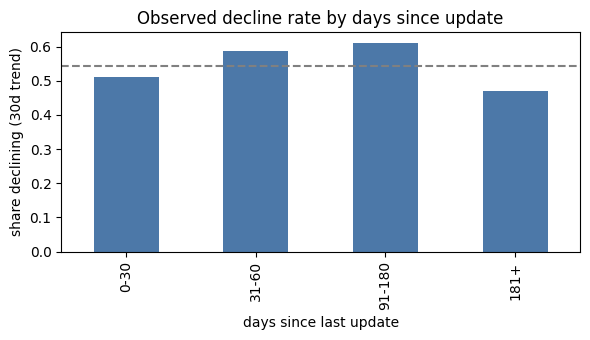

In [2]:
import matplotlib.pyplot as plt
df["stale_bucket"] = pd.cut(df.days_since_last_update, [-1, 30, 60, 90, 180, 10**6],
                            labels=["0-30","31-60","61-90","91-180","181+"])
decay = df.groupby("stale_bucket", observed=True).y.agg(n="size", decline_rate="mean").round(3)
display(decay)

os.makedirs("work/figures", exist_ok=True); os.makedirs("work/outputs", exist_ok=True)
ok = decay[decay.n >= 50]
ax = ok.decline_rate.plot(kind="bar", color="#4C78A8", figsize=(6, 3.5))
ax.axhline(base, ls="--", color="gray"); ax.set_ylabel("share declining (30d trend)")
ax.set_xlabel("days since last update"); ax.set_title("Observed decline rate by days since update")
plt.tight_layout(); plt.savefig("work/figures/decline_by_staleness.png", dpi=150); plt.show()

Observed decline rates by archetype (this sample): THIN_VISIBLE 0.78 (n=426), CTR_GAP_PAGE1 0.76 (n=649), STRIKING_DISTANCE 0.61 (n=3,897), STALE_VISIBLE 0.60 (n=7,095) and LOW_PRIORITY 0.49 (n=17,933), against an overall rate of about 0.54. The archetype rules use only position, impressions, CTR gap, word count and staleness (never the label), so these rates are descriptive checks, not fitted results. The two smallest archetypes have the highest rates but also the smallest samples.

## 2. Intended use and limits
Intended use: decision-support for a human content reviewer deciding which pages to look at first. The queue orders review work; it does not decide what to change.

Validation behind the queue: every page is scored by a Logistic Regression that never saw that page's client (5-fold GroupKFold by client_id, out-of-fold). Pooled over all pages: P@50 = 0.82, P@100 = 0.76, average precision = 0.645, against a base rate of 0.542. Within each held-out fold, P@50 ranged from 0.72 to 0.88 (mean about 0.77), so the pooled number is the upper end of a wide range. Modest and directional.

Limits:
- The target is a 30-day impressions trend (trend_direction == "down"), a short window that can be noise.
- The 90-day features overlap with the 30 days that define the label (correlation 0.92 for impressions), so performance may be overstated.
- A random row split gave higher numbers than the client-grouped split in my Week-6 audit (P@50 0.87 vs 0.77), so random-split numbers should never be quoted for this queue.
- The data is a 30,000-page anonymized sample from a small set of clients (one client holds 23% of rows); results may not transfer to other clients, and the large PSI values between client groups (Section 4) point the same way.
- The model sees no recent trend, so it can rank a recovering page as at-risk.
- The top of the queue is dominated by high-impression pages with CTR near 0.00. Some may be impression-count artifacts rather than real missed clicks, so a reviewer should confirm the numbers in Search Console before acting.
- Action rules are heuristics based on the paper's playbook ideas; I did not test that any action improves performance.

## 3. Human review + the no-go list

Human-review rules:
- A reviewer opens each page and reads the reason code, the numbers behind it and the "what would make this wrong" note before acting.
- Check intent match, seasonality and SERP features (ads, snippets) before changing a title or content. For top-ranked pages with CTR near 0.00 and very high impressions, confirm the figures in Search Console first, since they may be impression artifacts.
- No page is edited, merged or removed because of its score alone. A reviewer approves every action and records the outcome (acted / skipped / why).
- Review the top of the queue in batches of 50 pages, not the whole list at once.

Cost/value (assumption: 15 minutes per page review, my own estimate, not measured): reviewing the top 100 pages takes about 25 hours and surfaces 79 pages with a declining 30-day trend, against about 54 expected from random order, so about 25 extra declining pages found. At 200 pages the extra grows to about 40 but costs 50 hours, so the first 100 pages give the best return per hour. Precision in the top 50 to 200 stays at 0.74 to 0.79 against a base rate of 0.54. Value here means review efficiency only; I did not measure any traffic or revenue gain from acting on these pages. Directional, decision-support only.

No-go list (do NOT automate):
- Publishing, rewriting or deleting content automatically from the score.
- Using the score to judge writers, clients or content quality.
- Quoting the score as a prediction of Google rankings or traffic.
- Treating a reason code as a cause (for example "stale means it declined because it is stale").
- Applying the queue to a new client without re-checking it on that client.

In [3]:
rows = []
for k in [50, 100, 200]:
    p = precision_at_k(queue.y, queue.priority, k)
    rows.append({"pages_reviewed": k, "precision_declining": round(p, 3),
                 "declining_found": round(p*k), "random_expected": round(base*k),
                 "review_hours_at_15min": k*0.25})
cost_value = pd.DataFrame(rows)
cost_value

,pages_reviewed,precision_declining,declining_found,random_expected,review_hours_at_15min
0,50,0.78,39,27,12.5
1,100,0.79,79,54,25.0
2,200,0.74,148,108,50.0


## 4. Monitoring / retrain triggers

Light monitoring (a plan, not a production system). Run on each new data refresh or new client batch:

- Quality check: compute P@50 once labels exist. In my five client-grouped folds P@50 was 0.72, 0.72, 0.74, 0.78 and 0.88 (base rate 0.54), so a single result inside that range is normal noise. If P@50 falls below the base rate plus 0.05 (about 0.59) for two refreshes in a row, pause use of the queue and review it.
- Drift check: compute PSI for impressions, position, CTR and days since update, comparing the new batch against the training data. Rule-of-thumb thresholds (not tuned to this data): below 0.1 stable, 0.1 to 0.25 look closer, above 0.25 retrain candidate.
- Observed in my data: comparing one held-out client group against the rest gave PSI of 0.91 for impressions, 1.42 for days since update, 0.18 for CTR and 0.10 for position. These large values show how different clients are from each other, not drift over time, so any new client should trigger a fresh check before the queue is used on it.
- Reviewer feedback: if reviewers mark more than half of the top-50 pages as "wrong", investigate before the next batch.
- Retrain triggers: a new client or client set, PSI above 0.25 on two or more features, a change in how the label or trend is computed, or at least one quarter of new data. After any retrain, re-run the client-grouped validation audit before using the new queue.

In [4]:
def psi(ref, new, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref); n = np.histogram(new, edges)[0] / len(new)
    r, n = np.clip(r, 1e-4, None), np.clip(n, 1e-4, None)
    return float(np.sum((n - r) * np.log(n / r)))

# stability across client folds (each fold = unseen clients)
fold_p50 = []
for tr, te in gkf.split(df, df.y, groups=df.client_id):
    fold_p50.append(precision_at_k(df.y.iloc[te], df.decline_risk.iloc[te], 50))
print("P@50 per fold:", np.round(fold_p50, 2), "| range", round(min(fold_p50), 2), "-", round(max(fold_p50), 2))

# example drift check: first fold's clients vs the rest (stand-in for "new batch vs training data")
tr, te = next(gkf.split(df, df.y, groups=df.client_id))
for c in ["impressions_90d", "avg_position", "ctr", "days_since_last_update"]:
    print(c, "PSI:", round(psi(df[c].iloc[tr], df[c].iloc[te]), 3))

P@50 per fold: [0.72 0.72 0.74 0.78 0.88] | range 0.72 - 0.88
impressions_90d PSI: 0.913
avg_position PSI: 0.1
ctr PSI: 0.179
days_since_last_update PSI: 1.42


## 5. Exports for the paper
Exports for the paper: work/outputs/action_queue.csv (the ranked queue with reason codes and actions; regenerated by this notebook and kept out of git), work/outputs/w07_metrics.json (the numbers behind the paper's claims: out-of-fold P@50, P@100, average precision, per-fold P@50 and reason-code counts) and work/figures/decline_by_staleness.png (observed decline rate by days since last update).

In [5]:
export_cols = ["rank","content_id","priority","decline_risk","reason_code","action",
               "avg_position","impressions_90d","ctr","days_since_last_update"]
os.makedirs("work/outputs", exist_ok=True)
queue[export_cols].round(4).to_csv("work/outputs/action_queue.csv", index=False)

metrics = {"n_pages": int(len(df)), "base_decline_rate": round(float(base), 3),
           "oof_p_at_50": precision_at_k(df.y, df.decline_risk, 50),
           "oof_p_at_100": precision_at_k(df.y, df.decline_risk, 100),
           "oof_average_precision": round(float(average_precision_score(df.y, df.decline_risk)), 3),
           "fold_p_at_50": [round(float(x), 3) for x in fold_p50],
           "reason_code_counts": df.reason_code.value_counts().to_dict(),
           "validation": "5-fold GroupKFold by client_id, out-of-fold scores"}
json.dump(metrics, open("work/outputs/w07_metrics.json", "w"), indent=2)
print(os.listdir("work/outputs"), os.listdir("work/figures"))

['action_queue.csv', 'w07_metrics.json'] ['decline_by_staleness.png']


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.